<a href="https://colab.research.google.com/github/gokulakrishnan1226/Stock_price_prediction_LSTM/blob/main/Stock_price_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q yfinance scipy scikit-learn tensorflow matplotlib pandas numpy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import scipy

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
tf.random.set_seed(42)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("TensorFlow:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
TensorFlow: 2.21.0
GPU available: False


In [3]:
TICKER = "AAPL"
RECORDS = 2000

data = yf.download(
    TICKER,
    period="max",
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Handle both ordinary and multi-level column formats.
if isinstance(data.columns, pd.MultiIndex):
    if TICKER in data.columns.get_level_values(-1):
        data = data.xs(TICKER, axis=1, level=-1)
    else:
        data.columns = data.columns.get_level_values(0)

# Keep the closing price and clean missing values.
data = data[["Close"]].copy()
data["Close"] = pd.to_numeric(data["Close"], errors="coerce")
data = data.dropna()
data = data[~data.index.duplicated(keep="last")]
data = data.sort_index()

# Select the latest 2,000 valid daily observations.
if len(data) < RECORDS:
    raise ValueError(
        f"Only {len(data)} valid records available. "
        "Choose a stock with more historical data."
    )

data = data.tail(RECORDS)

print("Stock:", TICKER)
print("Number of records:", len(data))
print("First date:", data.index.min().date())
print("Last date:", data.index.max().date())
display(data.head())
display(data.tail())

Stock: AAPL
Number of records: 2000
First date: 2018-11-05
Last date: 2026-10-21


Price,Close
Date,
2018-11-05,47.623264
2018-11-06,48.138283
2018-11-07,49.598217
2018-11-08,49.425167
2018-11-09,48.472168


Price,Close
Date,
2026-10-15,342.000000
2026-10-16,343.459991
2026-10-19,342.940002
2026-10-20,339.500000
2026-10-21,343.989990


Missing values:
 Price
Close    0
dtype: int64

Duplicate dates: 0

Dataset summary:


Price,Close
count,2000.000000
mean,160.691502
std,74.524215
min,33.707932
25%,115.354038
50%,158.464333
75%,211.933361
max,343.989990


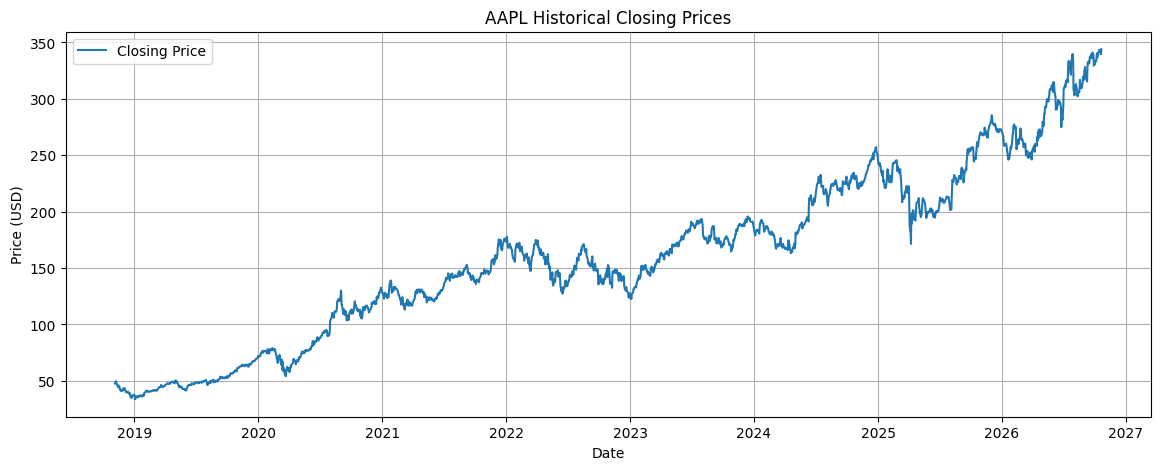

In [4]:
print("Missing values:\n", data.isnull().sum())
print("\nDuplicate dates:", data.index.duplicated().sum())
print("\nDataset summary:")
display(data.describe())

plt.figure(figsize=(14, 5))
plt.plot(data.index, data["Close"], label="Closing Price")
plt.title(f"{TICKER} Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
LOOKBACK = 60

prices = data["Close"].values.reshape(-1, 1)
dates = data.index

split_index = int(len(prices) * 0.80)

# Fit the scaler only on training prices.
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(prices[:split_index])

# Transform the entire series using the training-fitted scaler.
scaled_prices = scaler.transform(prices)

def create_sequences(values, lookback):
    X, y, target_indices = [], [], []

    for i in range(lookback, len(values)):
        X.append(values[i - lookback:i])
        y.append(values[i, 0])
        target_indices.append(i)

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(target_indices)
    )

X, y, target_indices = create_sequences(
    scaled_prices, LOOKBACK
)

# Separate training and testing sequences by target date.
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

test_indices = target_indices[test_mask]
test_dates = dates[test_indices]

print("Original records:", len(data))
print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)
print("Input shape:", X_train.shape[1:])
print("Output shape:", y_train.shape)

Original records: 2000
Training sequences: (1540, 60, 1)
Testing sequences: (400, 60, 1)
Input shape: (60, 1)
Output shape: (1540,)


In [30]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, 1)),

    layers.LSTM(
        32,
        kernel_regularizer=keras.regularizers.l2(0.0001)
    ),

    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
scale_factor = tf.constant(
    float(scaler.scale_[0]), dtype=tf.float32
)

scale_offset = tf.constant(
    float(scaler.min_[0]), dtype=tf.float32
)

def accuracy_within_5_percent(y_true, y_pred):
    y_true = tf.reshape(
        tf.cast(y_true, tf.float32),
        tf.shape(y_pred)
    )
    y_pred = tf.cast(y_pred, tf.float32)

    actual_price = (y_true - scale_offset) / scale_factor
    predicted_price = (y_pred - scale_offset) / scale_factor

    relative_error = (
        tf.abs(actual_price - predicted_price)
        / tf.maximum(tf.abs(actual_price), 1e-7)
    )

    return tf.reduce_mean(
        tf.cast(relative_error <= 0.05, tf.float32)
    )

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        accuracy_within_5_percent
    ]
)

In [32]:
import tensorflow as tf
from tensorflow import keras

scale_factor = tf.constant(
    float(scaler.scale_[0]), dtype=tf.float32
)
scale_offset = tf.constant(
    float(scaler.min_[0]), dtype=tf.float32
)

def accuracy_within_5_percent(y_true, y_pred):
    y_true = tf.reshape(
        tf.cast(y_true, tf.float32),
        tf.shape(y_pred)
    )
    y_pred = tf.cast(y_pred, tf.float32)

    actual = (y_true - scale_offset) / scale_factor
    predicted = (y_pred - scale_offset) / scale_factor

    relative_error = (
        tf.abs(actual - predicted)
        / tf.maximum(tf.abs(actual), 1e-7)
    )

    return tf.reduce_mean(
        tf.cast(relative_error <= 0.05, tf.float32)
    )

In [35]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.10,
    shuffle=False,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy_within_5_percent: 0.4097 - loss: 0.0036 - mae: 0.0434 - val_accuracy_within_5_percent: 0.3082 - val_loss: 0.0055 - val_mae: 0.0659 - learning_rate: 3.0000e-04
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy_within_5_percent: 0.3783 - loss: 0.0038 - mae: 0.0449 - val_accuracy_within_5_percent: 0.3346 - val_loss: 0.0052 - val_mae: 0.0639 - learning_rate: 3.0000e-04
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy_within_5_percent: 0.4423 - loss: 0.0038 - mae: 0.0428 - val_accuracy_within_5_percent: 0.3236 - val_loss: 0.0050 - val_mae: 0.0628 - learning_rate: 3.0000e-04
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy_within_5_percent: 0.4217 - loss: 0.0034 - mae: 0.0418 - val_accuracy_within_5_percent: 0.2303 - val_loss: 0.0065 - val_mae: 0.0732 - learning_rate: 3.0000e-04
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy_within_5_percent: 0.4358 - loss: 0.0033 - mae: 0.0410 

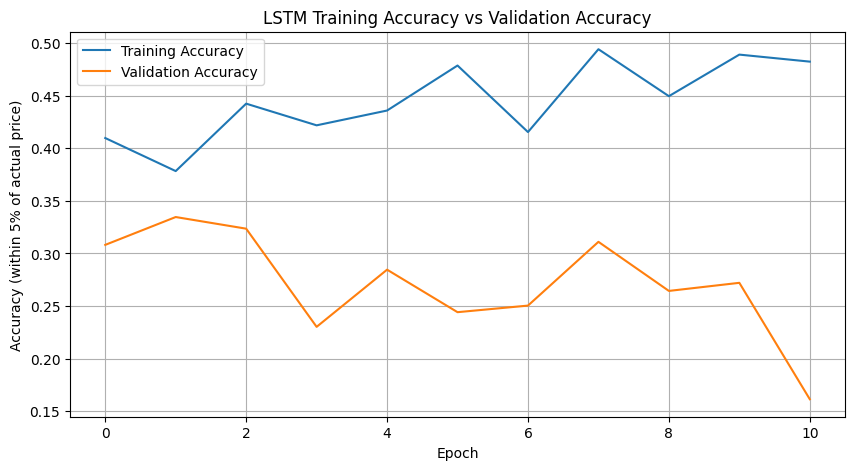

Final training accuracy: 48.22%
Final validation accuracy: 16.15%


In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Use the registered custom metric names for 5%
plt.plot(
    history.history["accuracy_within_5_percent"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy_within_5_percent"],
    label="Validation Accuracy"
)

plt.title("LSTM Training Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (within 5% of actual price)")
plt.legend()
plt.grid(True)
plt.show()

print(
    "Final training accuracy:",
    f"{history.history['accuracy_within_5_percent'][-1] * 100:.2f}%"
)

print(
    "Final validation accuracy:",
    f"{history.history['val_accuracy_within_5_percent'][-1] * 100:.2f}%"
)

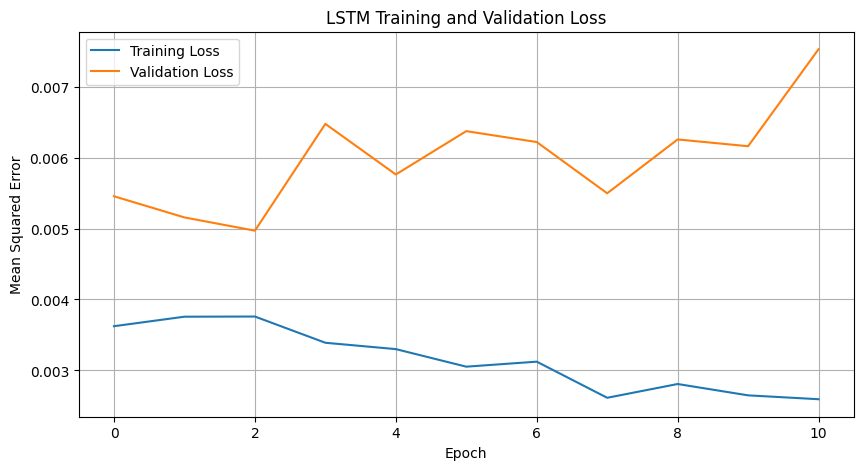

In [41]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [42]:
# Predict normalized closing prices.
predicted_scaled = model.predict(X_test, verbose=0)

# Convert normalized prices back to actual prices.
predicted_prices = scaler.inverse_transform(predicted_scaled).ravel()
actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

# Calculate evaluation metrics.
mae = mean_absolute_error(actual_prices, predicted_prices)
rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))

# Simple baseline: predict tomorrow's price equals today's price.
baseline_prices = prices[test_indices - 1, 0]

baseline_mae = mean_absolute_error(actual_prices, baseline_prices)
baseline_rmse = np.sqrt(
    mean_squared_error(actual_prices, baseline_prices)
)

print(f"Stock: {TICKER}")
print(f"Test records: {len(actual_prices)}")
print(f"LSTM MAE: ${mae:.4f}")
print(f"LSTM RMSE: ${rmse:.4f}")
print(f"Baseline MAE: ${baseline_mae:.4f}")
print(f"Baseline RMSE: ${baseline_rmse:.4f}")

Stock: AAPL
Test records: 400
LSTM MAE: $22.2683
LSTM RMSE: $25.2484
Baseline MAE: $3.1062
Baseline RMSE: $4.5626


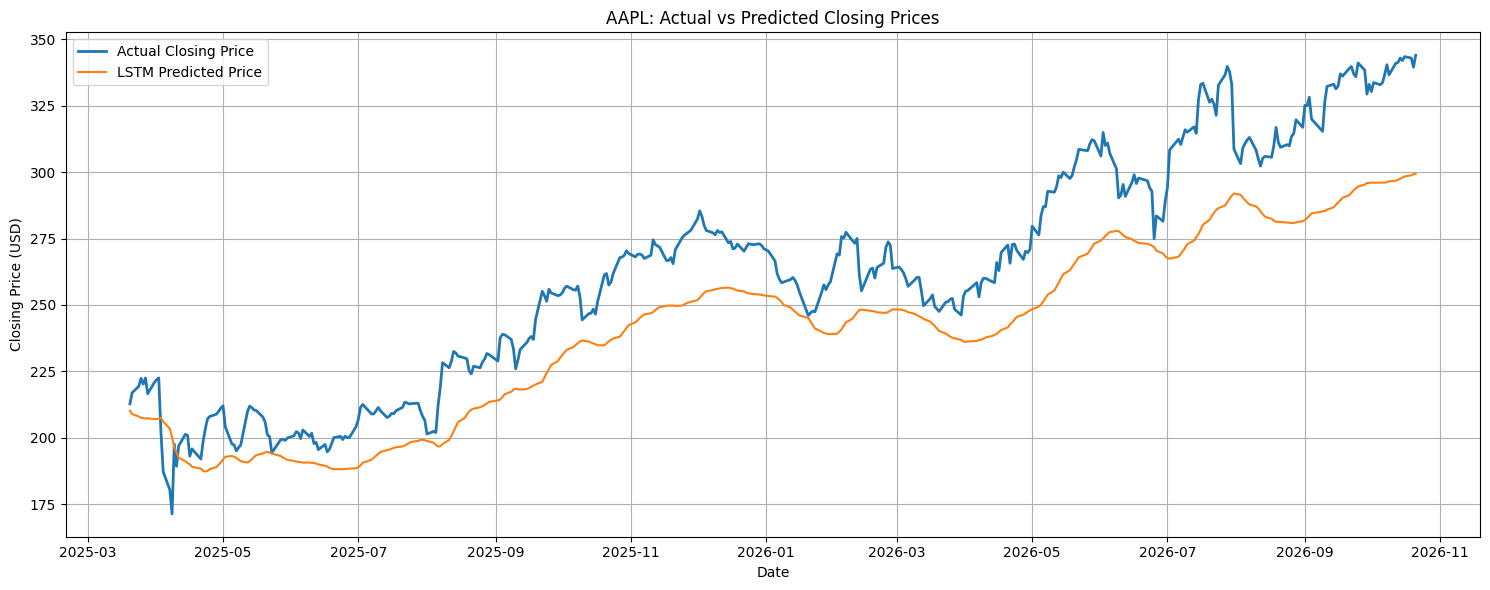

In [43]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    actual_prices,
    label="Actual Closing Price",
    linewidth=2
)

plt.plot(
    test_dates,
    predicted_prices,
    label="LSTM Predicted Price",
    linewidth=1.5
)

plt.title(f"{TICKER}: Actual vs Predicted Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

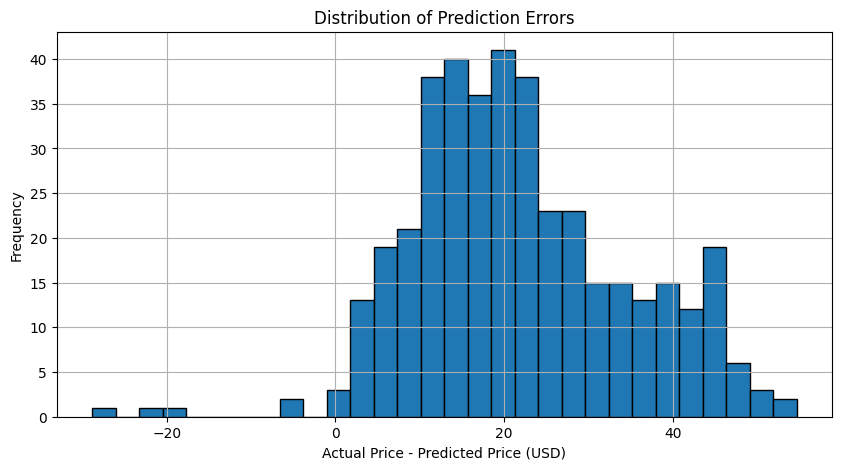

Mean prediction error: 21.8607


In [44]:
errors = actual_prices - predicted_prices

plt.figure(figsize=(10, 5))
plt.hist(errors, bins=30, edgecolor="black")
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Price - Predicted Price (USD)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

print("Mean prediction error:", round(float(errors.mean()), 4))

In [45]:
FORECAST_DAYS = 5

# Start with the last 60 known normalized closing prices.
last_window = scaled_prices[-LOOKBACK:].copy()

future_predictions = []

for _ in range(FORECAST_DAYS):
    # Model expects shape: (batch, timesteps, features)
    next_scaled = model.predict(
        last_window.reshape(1, LOOKBACK, 1),
        verbose=0
    )[0, 0]

    future_predictions.append(next_scaled)

    # Remove the oldest observation and append the prediction.
    last_window = np.vstack([
        last_window[1:],
        [[next_scaled]]
    ])

# Return predictions to the original price scale.
future_prices = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1, 1)
).ravel()

# Approximate future business days; exchange holidays are not excluded.
future_dates = pd.bdate_range(
    start=data.index[-1] + pd.Timedelta(days=1),
    periods=FORECAST_DAYS
)

forecast_df = pd.DataFrame({
    "Forecast Date": future_dates.date,
    "Predicted Closing Price": np.round(future_prices, 2)
})

display(forecast_df)

,Forecast Date,Predicted Closing Price
0,2026-10-22,299.730011
1,2026-10-23,298.109985
2,2026-10-26,295.929993
3,2026-10-27,293.559998
4,2026-10-28,291.070007


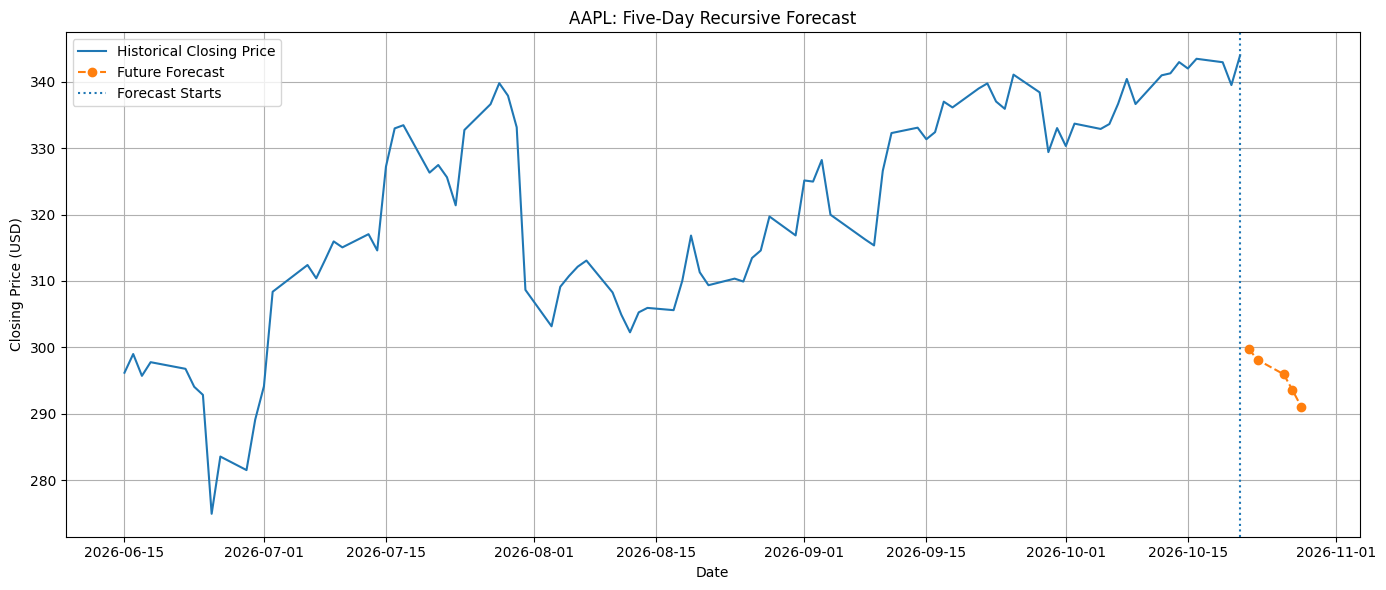

In [46]:
plt.figure(figsize=(14, 6))

# Display the last 90 known observations.
plt.plot(
    data.index[-90:],
    data["Close"].iloc[-90:].values,
    label="Historical Closing Price"
)

plt.plot(
    future_dates,
    future_prices,
    marker="o",
    linestyle="--",
    label="Future Forecast"
)

plt.axvline(
    data.index[-1],
    linestyle=":",
    label="Forecast Starts"
)

plt.title(f"{TICKER}: Five-Day Recursive Forecast")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()